# El puntaje, el modelo nulo y el intervalo: juzgar una predicción cuando la campaña queda fuera

**Pregunta:** ¿Qué significa un puntaje cuando la campaña queda fuera, y qué tan ancho es su intervalo honesto?

**Nivel 2: El método en la práctica** · Requiere: 04-benchmark-protocol/01-three-ways-to-split-the-same-97-blasts · Tiempo de lectura: unos 35 minutos

## Objetivos

Un número como "R2 = 0,94" no significa nada hasta que se nombra el estadístico, se pone una línea base a su lado y se declara la incertidumbre. Este notebook construye las tres cosas que el producto informa con cada puntaje, sobre predictores que realmente quedan fuera por campaña.

Al terminar habrá:

- visto dos estadísticos que comparten nombre dar números distintos para las mismas predicciones, y elegido uno;
- puntuado el modelo nulo y tres predictores aprendidos con cada campaña fuera, y descubierto por qué el nulo es una vara de medir pobre;
- construido un intervalo de 95 por ciento que remuestrea tiros y otro que remuestrea campañas, y medido cuánto más ancho es el honesto;
- encontrado qué campañas deciden el puntaje agrupado, que es la razón por la que el intervalo es ancho.

## Preparación

Instale los paquetes con los pines exactos de `notebooks/requirements.txt`. El motor es `blastfrag`, publicado en PyPI; los otros paquetes son su base numérica y la biblioteca de gráficos.

```bash
pip install blastfrag==0.4.0 numpy==2.5.4 matplotlib==3.11.2
```

Una sola celda hace toda la preparación: importa los paquetes, imprime sus versiones instaladas para que la salida registre qué motor produjo cada número que sigue, define el ayudante de tablas y carga los 97 tiros de entrenamiento.

In [1]:
# Importaciones, las versiones detrás de cada número, un ayudante de tablas y el corpus
from importlib.metadata import version

import blastfrag as bf
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import HTML, display

for name in ("blastfrag", "numpy", "matplotlib"):
    print(f"{name}=={version(name)}")


def show_table(columns, rows):
    # pandas no forma parte del entorno de notebooks, así que una tabla es una tabla HTML simple
    head = "".join(f"<th>{c}</th>" for c in columns)
    body = "".join("<tr>" + "".join(f"<td>{v}</td>" for v in row) + "</tr>" for row in rows)
    display(HTML(f"<table><thead><tr>{head}</tr></thead><tbody>{body}</tbody></table>"))


train = bf.load_training_corpus()

blastfrag==0.4.0
numpy==2.5.4
matplotlib==3.11.2


## Datos

| Fuente | Titular y URL | Clase de licencia | Archivo que lee el notebook |
|---|---|---|---|
| Los 97 tiros | Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957 | hechos numéricos reutilizados con cita; el artículo nunca se distribuye | el corpus dentro del paquete `blastfrag` |
| Los 12 tiros de validación publicados | Kulatilake, Hudaverdi y Wu 2012, https://doi.org/10.1007/s10706-012-9496-3 (Tables 4 y 5) | hechos numéricos reutilizados con cita; el artículo nunca se distribuye | dentro del paquete `blastfrag`, `bf.load_holdout()` |

Todo número que sigue se recalcula desde los 97 tiros de entrenamiento y los 12 tiros de validación; el notebook no lee ningún puntaje horneado.

## Método

**El estadístico.** Dos cantidades llevan el nombre R2 en esta literatura, y el motor informa cada una con su propio nombre. `pearson_r2` es la correlación al cuadrado de predicho contra medido; es ciega a un desplazamiento constante o a una escala equivocada. `r2_identity = 1 - sum((medido - predicho)^2) / sum((medido - promedio(medido))^2)` es la varianza explicada respecto de la línea identidad, y es negativa cuando las predicciones son peores que el promedio de las mediciones.

**El nulo.** Un modelo que predice el tamaño medido promedio de sus filas de entrenamiento y no usa ninguna entrada. Se reajusta dentro de cada pliegue, como debe hacerse con cualquier modelo.

**El intervalo.** Un bootstrap que remuestrea la unidad de independencia. Los tiros de una campaña comparten una masa rocosa, un equipo de perforación y un suministro de explosivo, así que bajo un protocolo que deja campañas fuera la unidad independiente es la campaña (Roberts et al. 2017, https://doi.org/10.1111/ecog.02881). Qué mirar: qué tan lejos pueden estar los dos estadísticos, si el nulo queda en cero como cabría esperar, y cuántas veces más ancho es el intervalo por campaña.

### Paso 1: un conjunto de predicciones, dos estadísticos

Los 12 tiros de validación de Kulatilake, Hudaverdi y Wu 2012 son el conjunto en el que la literatura reporta R2. La celda puntúa el predictor clásico en ellos con `score`, que entrega ambos estadísticos, e imprime su razón.

In [2]:
# Dos estadísticos sobre las mismas predicciones: el predictor clásico en los 12 tiros de validación publicados
holdout = bf.load_holdout()
classical = bf.default_arms()["kuznetsov"]().fit(train)
published_set = bf.score(holdout, classical.predict(holdout))
rows = [
    ("pearson_r2", f"{published_set.pearson_r2:.4f}", "correlación al cuadrado de predicho contra medido"),
    ("r2_identity", f"{published_set.r2_identity:.4f}", "varianza explicada respecto de la línea identidad"),
    ("RMSE (m)", f"{published_set.rmse_m:.4f}", "error típico en la unidad del tamaño"),
]
show_table(["estadístico", "valor", "qué mide"], rows)
ratio = published_set.pearson_r2 / published_set.r2_identity
print(f"tiros puntuados: {published_set.n_scored} | razón de los dos estadísticos: {ratio:.2f}")

estadístico,valor,qué mide
pearson_r2,0.5674,correlación al cuadrado de predicho contra medido
r2_identity,0.2284,varianza explicada respecto de la línea identidad
RMSE (m),0.1282,error típico en la unidad del tamaño


tiros puntuados: 12 | razón de los dos estadísticos: 2.48


Las mismas 12 predicciones puntúan 0,5674 como correlación al cuadrado y 0,2284 como varianza explicada respecto de la línea identidad, una razón de 2,48, con una raíz del error cuadrático medio de 0,1282 m. Nada cambió en las predicciones entre los dos números; la correlación al cuadrado perdona una escala equivocada o un desplazamiento constante, y el estadístico de la línea identidad cobra ambos. Un artículo que reporta "R2 = 0,57" y otro que reporta "R2 = 0,23" pueden describir el mismo predictor. La tabla no dice qué estadístico es correcto en general: el criterio del producto está escrito sobre `r2_identity`, porque un usuario necesita el tamaño predicho mismo, y `pearson_r2` se informa a su lado para poder compararlo con la literatura.

### Paso 2: cada campaña fuera por turno

Desde aquí la unidad es la campaña. La celda entrena el nulo y tres predictores aprendidos (gradient boosting, un bosque aleatorio y el ensamble de apilamiento) con nueve campañas, predice la décima y reúne la predicción fuera de pliegue de los 97 tiros. `default_arms` entrega fábricas, de modo que cada pliegue recibe un modelo nuevo.

In [3]:
# Una campaña fuera para el nulo y tres predictores aprendidos, reuniendo cada predicción fuera de pliegue
factories = bf.default_arms()
names = ["null", "xgboost", "random-forest", "stacking"]
tested, predictions = [], {name: [] for name in names}
for fold in bf.leave_one_site_out(train):
    tested += list(fold.test)
    for name in names:
        model = factories[name]().fit(fold.train)
        predictions[name] += model.predict(fold.test)
rows = []
for name in names:
    abstained = sum(p.abstained for p in predictions[name])
    rows.append((name, factories[name]().tier, len(predictions[name]), abstained))
show_table(["predictor", "nivel", "predicciones fuera de pliegue", "abstenciones"], rows)

predictor,nivel,predicciones fuera de pliegue,abstenciones
null,control,97,0
xgboost,learned,97,0
random-forest,learned,97,0
stacking,learned,97,0


Los cuatro predictores responden a cada uno de los 97 tiros, sin abstención, así que los cuatro puntajes que siguen son sobre las mismas filas y no necesitan reserva por conjunto de filas. Cada tiro es predicho por un modelo que nunca vio su campaña: los 97 valores son las predicciones fuera de pliegue de diez modelos ajustados distintos, uno por pliegue, agrupadas. La tabla no muestra los puntajes de cada pliegue; el paso 6 vuelve sobre por qué importa agruparlos.

### Paso 3: los puntajes, y las predicciones detrás de ellos

La celda puntúa cada predictor en los 97 tiros con ambos estadísticos y la raíz del error cuadrático medio, y luego grafica predicho contra medido con la línea identidad, un panel por predictor. El nulo es la línea base: un predictor que no lo supera no ha aprendido nada que se transfiera.

predictor,pearson_r2,r2_identity,RMSE (m)
null,0.6268,-0.2163,0.2067
xgboost,0.1633,-0.0342,0.1906
random-forest,0.1034,-0.2315,0.2080
stacking,0.1644,-0.0345,0.1906


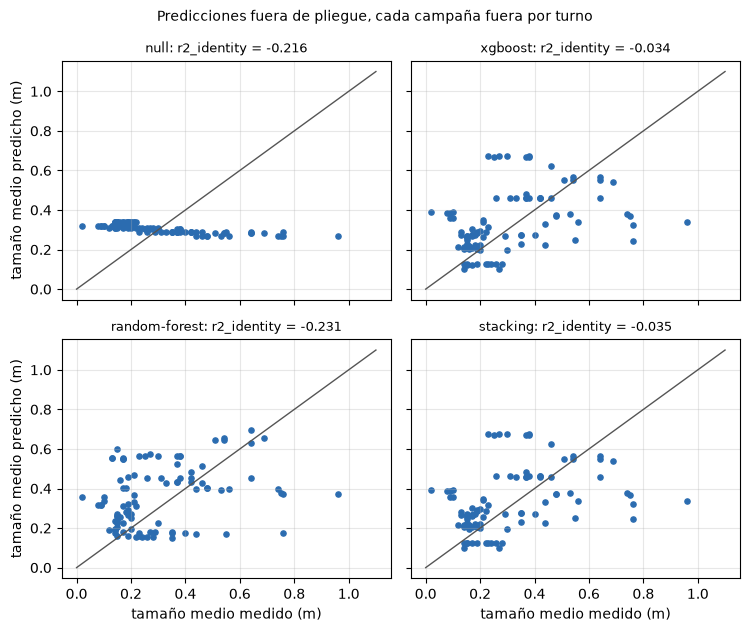

In [4]:
# Puntuar cada predictor con una campaña fuera con ambos estadísticos, y graficar predicho contra medido
scores = {name: bf.score(tested, predictions[name], method=name) for name in names}
rows = []
for name, s in scores.items():
    pearson = "-" if s.pearson_r2 is None else f"{s.pearson_r2:.4f}"
    rows.append((name, pearson, f"{s.r2_identity:.4f}", f"{s.rmse_m:.4f}"))
show_table(["predictor", "pearson_r2", "r2_identity", "RMSE (m)"], rows)

measured = np.array([blast.x50_m for blast in tested])
fig, axes = plt.subplots(2, 2, figsize=(7.6, 6.4), sharex=True, sharey=True)
for ax, name in zip(axes.ravel(), names):
    predicted = np.array([p.x50_m for p in predictions[name]])
    ax.scatter(measured, predicted, s=14, color="#2b6cb0")
    ax.plot([0, 1.1], [0, 1.1], color="#555", lw=1)
    ax.set_title(f"{name}: r2_identity = {scores[name].r2_identity:.3f}", fontsize=9)
    ax.grid(alpha=0.3)
for ax in axes[1]:
    ax.set_xlabel("tamaño medio medido (m)")
for ax in axes[:, 0]:
    ax.set_ylabel("tamaño medio predicho (m)")
fig.suptitle("Predicciones fuera de pliegue, cada campaña fuera por turno", fontsize=10)
fig.tight_layout()
plt.show()

Por `pearson_r2` el nulo puntúa 0,6268 y quedaría primero de los cuatro, por delante de gradient boosting con 0,1633, el bosque aleatorio con 0,1034 y el apilamiento con 0,1644. Por `r2_identity` queda tercero, con -0,2163 frente a -0,0342, -0,2315 y -0,0345, y las raíces del error cuadrático medio, 0,2067 m, 0,1906 m, 0,2080 m y 0,1906 m, concuerdan con el segundo orden. Los paneles muestran por qué: el nulo es una línea horizontal que corta la línea identidad, sus predicciones casi no varían, y su correlación al cuadrado es alta solo porque varían en el sentido equivocado. Ningún predictor aprendido supera el cero, y el bosque aleatorio queda bajo el nulo. La figura no muestra qué campañas son responsables de la dispersión; eso lo aísla el jackknife del paso 6.

### Paso 4: por qué el nulo merece una segunda mirada

El nulo es la media de entrenamiento, y la media de entrenamiento se mueve cuando una campaña queda fuera: dejar fuera una campaña gruesa la baja, dejar fuera una fina la sube. La celda lista, para cada pliegue, el tamaño medio de la campaña por la que se pregunta y el número que el nulo predice para ella, y grafica uno contra el otro.

campaña fuera,su tamaño medio medido (m),predicción del nulo: media de entrenamiento (m)
Akdaglar,0.171,0.341
Dongri-Buzurg,0.413,0.291
Enusa,0.396,0.289
Miami,0.080,0.317
Mrica,0.166,0.320
Murgul,0.311,0.302
Ozmert,0.191,0.311
Reocin,0.616,0.267
Reocin-UG,0.593,0.283
Soma,0.224,0.309


correlación de las predicciones del nulo con las mediciones: -0.7917
correlación entre los diez pliegues: -0.8933


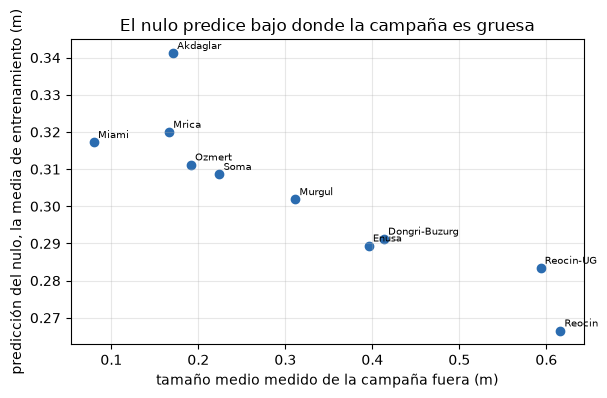

In [5]:
# Por qué el nulo no es neutral: su media de entrenamiento frente a la campaña por la que se pregunta
rows, held_means, train_means, sites = [], [], [], []
for fold in bf.leave_one_site_out(train):
    sites.append(fold.detail["held_out_site"])
    held_means.append(np.mean([blast.x50_m for blast in fold.test]))
    train_means.append(bf.training_mean(fold.train))
    rows.append((sites[-1], f"{held_means[-1]:.3f}", f"{train_means[-1]:.3f}"))
show_table(["campaña fuera", "su tamaño medio medido (m)", "predicción del nulo: media de entrenamiento (m)"], rows)
null_values = np.array([p.x50_m for p in predictions["null"]])
print(f"correlación de las predicciones del nulo con las mediciones: {np.corrcoef(measured, null_values)[0, 1]:.4f}")
print(f"correlación entre los diez pliegues: {np.corrcoef(held_means, train_means)[0, 1]:.4f}")

fig, ax = plt.subplots(figsize=(6.2, 4.0))
ax.scatter(held_means, train_means, color="#2b6cb0")
for site, x, y in zip(sites, held_means, train_means):
    ax.annotate(site, (x, y), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set_xlabel("tamaño medio medido de la campaña fuera (m)")
ax.set_ylabel("predicción del nulo, la media de entrenamiento (m)")
ax.set_title("El nulo predice bajo donde la campaña es gruesa")
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

Los diez puntos caen sobre una línea descendente: cuando Reocin, con 0,616 m, queda fuera el nulo predice 0,267 m, y cuando Miami, con 0,080 m, queda fuera predice 0,317 m, con una correlación de -0,8933 entre los pliegues y de -0,7917 entre las predicciones agrupadas y las mediciones. El cuadrado de este último número, 0,6268, es exactamente el `pearson_r2` del nulo del paso 3. Una campaña gruesa baja la media de entrenamiento y una fina la sube, de modo que el nulo siempre se equivoca en el sentido opuesto a la verdad. La figura muestra el mecanismo; no muestra cuánto del margen de un predictor aprendido sobre el nulo proviene de este efecto, por lo cual un margen solo no puede leerse como habilidad y el criterio del último notebook de este tema exige además un puntaje sobre cero.

### Paso 5: el intervalo, remuestreando tiros y remuestreando campañas

`bootstrap_interval` toma una `unit`. Con `unit="blast"` cada extracción remuestrea las 97 filas con reemplazo; con `unit="site"` remuestrea las diez campañas, cada una con todas sus filas. La celda calcula ambas para los cuatro predictores con 2000 extracciones y una semilla fija, y las dibuja lado a lado.

predictor,unidad,r2_identity,inferior,superior,ancho
null,blast,-0.2163,-0.327,-0.189,0.138
null,site,-0.2163,-1.284,-0.145,1.139
xgboost,blast,-0.0342,-0.382,0.208,0.591
xgboost,site,-0.0342,-2.232,0.418,2.650
random-forest,blast,-0.2315,-0.686,0.054,0.740
random-forest,site,-0.2315,-2.783,0.381,3.164
stacking,blast,-0.0345,-0.383,0.210,0.593
stacking,site,-0.0345,-2.254,0.423,2.677


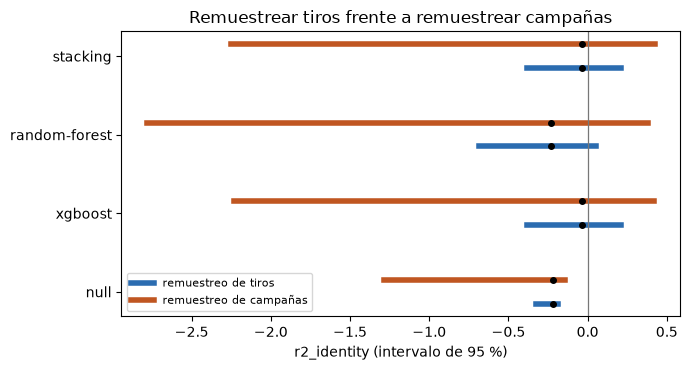

In [6]:
# Intervalos de 95 por ciento para los cuatro predictores con las dos unidades de remuestreo, 2000 extracciones
intervals = {}
rows = []
for name in names:
    for unit in ("blast", "site"):
        point, low, high = bf.bootstrap_interval(
            tested, predictions[name], "r2_identity", n_boot=2000, unit=unit, seed=0)
        intervals[name, unit] = (point, low, high)
        rows.append((name, unit, f"{point:.4f}", f"{low:.3f}", f"{high:.3f}", f"{high - low:.3f}"))
show_table(["predictor", "unidad", "r2_identity", "inferior", "superior", "ancho"], rows)

legend = {"blast": "remuestreo de tiros", "site": "remuestreo de campañas"}
fig, ax = plt.subplots(figsize=(7.0, 3.8))
for row, name in enumerate(names):
    for shift, unit, color in ((-0.15, "blast", "#2b6cb0"), (0.15, "site", "#c05621")):
        point, low, high = intervals[name, unit]
        ax.plot([low, high], [row + shift] * 2, lw=4, color=color, label=legend[unit] if row == 0 else None)
        ax.plot([point], [row + shift], "o", color="black", ms=4)
ax.axvline(0, color="#777", lw=0.9)
ax.set_yticks(range(len(names)), names)
ax.set_xlabel("r2_identity (intervalo de 95 %)")
ax.set_title("Remuestrear tiros frente a remuestrear campañas")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Remuestrear tiros le da a gradient boosting un intervalo de -0,382 a 0,208, un ancho de 0,591, mientras que remuestrear campañas da -2,232 a 0,418, un ancho de 2,650, y el mismo ensanchamiento aparece para el bosque aleatorio (0,740 frente a 3,164), el apilamiento (0,593 frente a 2,677) y el nulo (0,138 frente a 1,139). El intervalo por tiros trata las 97 filas como independientes y por eso parece preciso; el intervalo por campañas cuenta las diez unidades independientes y no puede descartar un puntaje muy por debajo de cero. Solo el intervalo por campañas del nulo, de -1,284 a -0,145, queda por completo bajo cero. La figura no dice que los intervalos por campañas sean exactos: un bootstrap de diez unidades es en sí mismo grueso, de modo que la cobertura real del intervalo honesto es incierta.

### Paso 6: qué campañas deciden el puntaje

Un intervalo por campaña es ancho cuando unas pocas campañas cargan el puntaje. Para ver cuáles, la celda quita cada campaña por turno de las predicciones fuera de pliegue agrupadas de gradient boosting y repuntúa el resto.

campaña quitada,r2_identity sin ella,cambio
Reocin,-0.2461,-0.2120
Reocin-UG,-0.2273,-0.1931
Akdaglar,-0.1563,-0.1221
Mrica,-0.0767,-0.0425
Enusa,-0.0561,-0.0219
Ozmert,-0.0557,-0.0216
Soma,-0.0283,+0.0059
Dongri-Buzurg,0.0051,+0.0392
Miami,0.0336,+0.0678
Murgul,0.2343,+0.2685


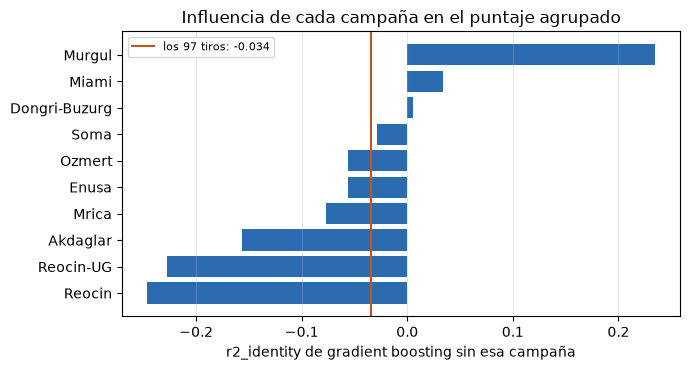

In [7]:
# Por qué el intervalo por campaña es ancho: quitar una campaña a la vez y repuntuar gradient boosting
full = bf.score(tested, predictions["xgboost"]).r2_identity
rows = []
for site in sorted({blast.site for blast in tested}):
    keep = [i for i, blast in enumerate(tested) if blast.site != site]
    without = bf.score([tested[i] for i in keep], [predictions["xgboost"][i] for i in keep]).r2_identity
    rows.append((site, without, without - full))
rows.sort(key=lambda row: row[1])
show_table(["campaña quitada", "r2_identity sin ella", "cambio"], [(s, f"{w:.4f}", f"{d:+.4f}") for s, w, d in rows])

fig, ax = plt.subplots(figsize=(7.0, 3.8))
ax.barh([row[0] for row in rows], [row[1] for row in rows], color="#2b6cb0")
ax.axvline(full, color="#c05621", lw=1.5, label=f"los 97 tiros: {full:.3f}")
ax.set_xlabel("r2_identity de gradient boosting sin esa campaña")
ax.set_title("Influencia de cada campaña en el puntaje agrupado")
ax.legend(fontsize=8)
ax.grid(alpha=0.3, axis="x")
fig.tight_layout()
plt.show()

El puntaje agrupado de gradient boosting es -0,0342, y quitar una sola campaña lo mueve hasta 0,2685. Sin Murgul es 0,2343, sin Miami 0,0336 y sin Dongri-Buzurg 0,0051, de modo que el signo del puntaje depende de si esas campañas se cuentan; sin Reocin cae a -0,2461, sin Reocin-UG a -0,2273 y sin Akdaglar a -0,1563. Esta es la razón por la que el intervalo por campañas es tan ancho: el puntaje lo cargan unas pocas campañas cuyos errores difieren en tamaño y en signo. La figura no dice por qué Murgul o Reocin se comportan como lo hacen; los errores por campaña de los notebooks siguientes parten de ahí.

## Resultados

**Respuesta:** con la campaña fuera, un puntaje significa algo solo junto al nulo y con un intervalo por campañas. El estadístico decide la historia: sobre las mismas 12 predicciones de validación `pearson_r2` es 0,5674 y `r2_identity` es 0,2284, y entre las diez campañas el nulo tiene un `pearson_r2` de 0,6268 pero un `r2_identity` de -0,2163. Gradient boosting puntúa -0,0342 y el apilamiento -0,0345, el bosque aleatorio -0,2315, de modo que ningún predictor aprendido está sobre cero y el bosque queda bajo el nulo. El intervalo honesto de 95 por ciento para gradient boosting remuestrea campañas y va de -2,232 a 0,418, un ancho de 2,650, frente a 0,591 cuando se remuestrean tiros. Una sola campaña mueve el puntaje de -0,0342 a 0,2343 (Murgul) o a -0,2461 (Reocin).

**Lo que esto no muestra.** No decide si algún predictor aprendido generaliza entre campañas, lo que requiere el criterio predeclarado del último notebook de este tema, y no explica por qué falla una campaña. El nulo no es una línea base neutral aquí, pues sus predicciones se correlacionan en -0,7917 con las mediciones, así que un margen sobre él es fácil de obtener sin habilidad. Un bootstrap sobre diez campañas es un instrumento tosco, y la cobertura de su intervalo es en sí misma incierta.

## Resumen

- Informe el estadístico por su nombre: las mismas 12 predicciones puntúan 0,5674 como `pearson_r2` y 0,2284 como `r2_identity`.
- El nulo se reajusta en cada pliegue y predice contra la verdad, así que su correlación al cuadrado es alta y su varianza explicada negativa.
- Remuestrear campañas ensancha el intervalo de gradient boosting de 0,591 a 2,650, porque unas pocas campañas cargan el puntaje agrupado.
- Siguiente: el notebook 03 ubica un puntaje publicado en la distribución de su propio protocolo (nivel 3).

## Referencias

- Roberts et al. 2017, https://doi.org/10.1111/ecog.02881 (remuestrear la unidad independiente)
- Kulatilake, Hudaverdi y Wu 2012, https://doi.org/10.1007/s10706-012-9496-3 (el conjunto de validación de 12 tiros donde dos estadísticos comparten nombre)
- Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957 (el corpus)
- `blastfrag` 0.4.0, el motor, en PyPI: https://pypi.org/project/blastfrag/